In [108]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
)
from xgboost import XGBClassifier


In [109]:
#read csv file
df = pd.read_csv("bank_marketing_full.csv", sep=";")


#Explore the dataset
print("Dataset shape:", df.shape)

print("Shape:", df.shape)
print("\nData types:")
display(df.dtypes)
print("\nTarget counts:")
display(df["y"].value_counts())


# Find missing values and duplicates
print("Missing value:", df.isna().sum().sum())
unknown_counts = (df == "unknown").sum()
print("Total unknown values for each column: \n", unknown_counts[unknown_counts > 0].sort_values(ascending=False))
print("Duplicate rows:", df.duplicated().sum())

df.head()

Dataset shape: (41188, 21)
Shape: (41188, 21)

Data types:


age                 int64
job                   str
marital               str
education             str
default               str
housing               str
loan                  str
contact               str
month                 str
day_of_week           str
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome              str
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                     str
dtype: object


Target counts:


y
no     36548
yes     4640
Name: count, dtype: int64

Missing value: 0
Total unknown values for each column: 
 default      8597
education    1731
housing       990
loan          990
job           330
marital        80
dtype: int64
Duplicate rows: 12


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


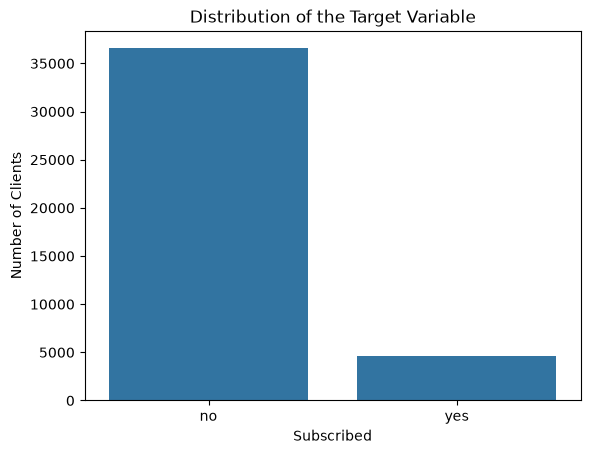

In [110]:
sns.countplot(data=df, x="y")
plt.title("Distribution of the Target Variable")
plt.xlabel("Subscribed")
plt.ylabel("Number of Clients")
plt.show()

## Basic data cleaning

Cells with “unknown” are actually missing values. To handle those, I keep those rows and then for each missing entry was then replaced with the most common value in that column. This avoids losing thousands of clients, although it may make common categories appear more frequent.

I used **one-hot encoding** as strategy to encode categorical columns. Each category is converted into its own binary 0 or 1 column. 

In [111]:
df = df.drop_duplicates().copy()
df = df.replace("unknown", np.nan)
print("Shape after removing duplicates:", df.shape)
print("\nMissing values:")
print(df.isna().sum()[df.isna().sum() > 0])

X = df.drop(columns="y")
y = df["y"].map({"no": 0, "yes": 1})
print(X.shape)
print(y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTraining proportions:")
print(y_train.value_counts(normalize=True))
print("\nTest proportions:")
print(y_test.value_counts(normalize=True))

Shape after removing duplicates: (41176, 21)

Missing values:
job           330
marital        80
education    1730
default      8596
housing       990
loan          990
dtype: int64
(41176, 20)
y
0    36537
1     4639
Name: count, dtype: int64
Training shape: (32940, 20)
Test shape: (8236, 20)

Training proportions:
y
0    0.887341
1    0.112659
Name: proportion, dtype: float64

Test proportions:
y
0    0.887324
1    0.112676
Name: proportion, dtype: float64


In [112]:
categorical_columns = X_train.select_dtypes(include=["object", "str", "string"]).columns.tolist()
numerical_columns = X_train.select_dtypes(include="number").columns.tolist()
print("Categorical columns:", categorical_columns)
print("Numerical columns:", numerical_columns)

Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Numerical columns: ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


In [114]:
# Preprocess categorical data with one-hot encoding and fill missing values.
categorical_pipeline = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore", sparse_output=False)
)

numerical_pipeline = make_pipeline(
    SimpleImputer(strategy="median")
)

preprocessor = ColumnTransformer([
    ("categorical", categorical_pipeline, categorical_columns),
    ("numerical", numerical_pipeline, numerical_columns)
])

In [115]:
models = {
    "ID3-style (Entropy)": DecisionTreeClassifier(
        criterion="entropy",
        max_depth=6,
        min_samples_leaf=10,
        random_state=42
    ),

    "CART (Gini)": DecisionTreeClassifier(
        criterion="gini",
        max_depth=6,
        min_samples_leaf=10,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=4,
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    )
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


## Cross-validation
I used stratified 5-fold cross-validation. Five folds give a stable performance estimate while keeping each validation set large enough to include a meaningful number of subscribers.

In [116]:
for model_name, model in models.items():
    model_pipeline = make_pipeline(preprocessor, model)
    scores = cross_validate(
        model_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy",
        n_jobs=1
    )
    print(f"{model_name}: 5-fold CV accuracy = {scores['test_score'].mean():.4f}")

ID3-style (Entropy): 5-fold CV accuracy = 0.9145
CART (Gini): 5-fold CV accuracy = 0.9145
Random Forest: 5-fold CV accuracy = 0.9093
Gradient Boosting: 5-fold CV accuracy = 0.9164
XGBoost: 5-fold CV accuracy = 0.9173


In [117]:
fitted_models = {}
test_predictions = {}

for model_name, model in models.items():
    model_pipeline = make_pipeline(preprocessor, model)
    model_pipeline.fit(X_train, y_train)
    predictions = model_pipeline.predict(X_test)

    fitted_models[model_name] = model_pipeline
    test_predictions[model_name] = predictions

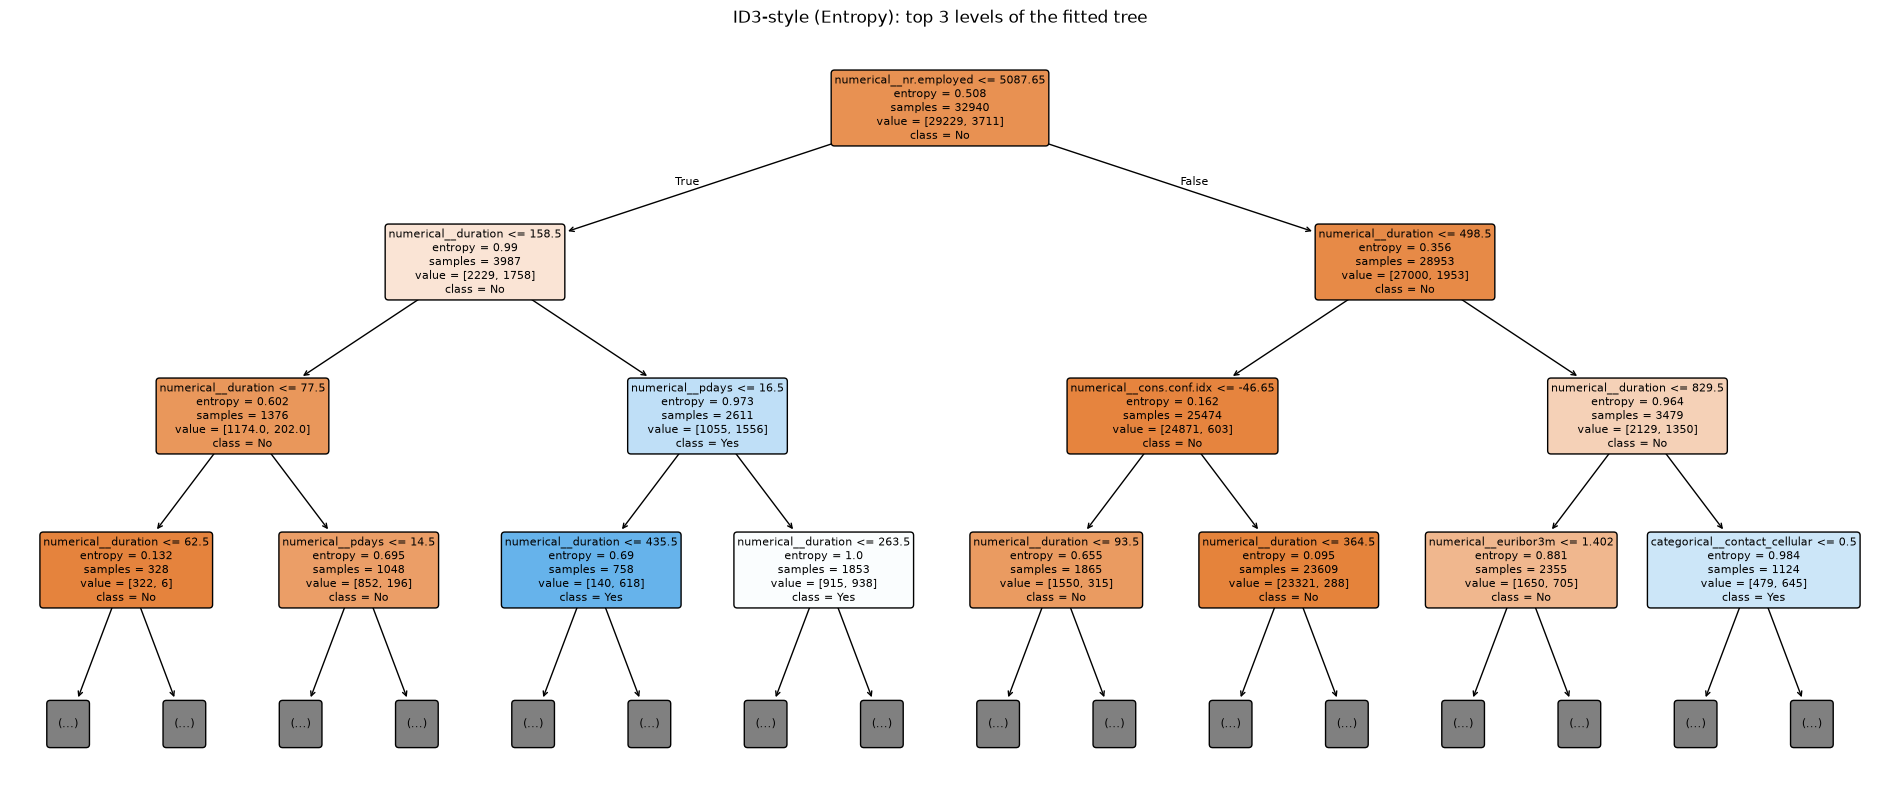

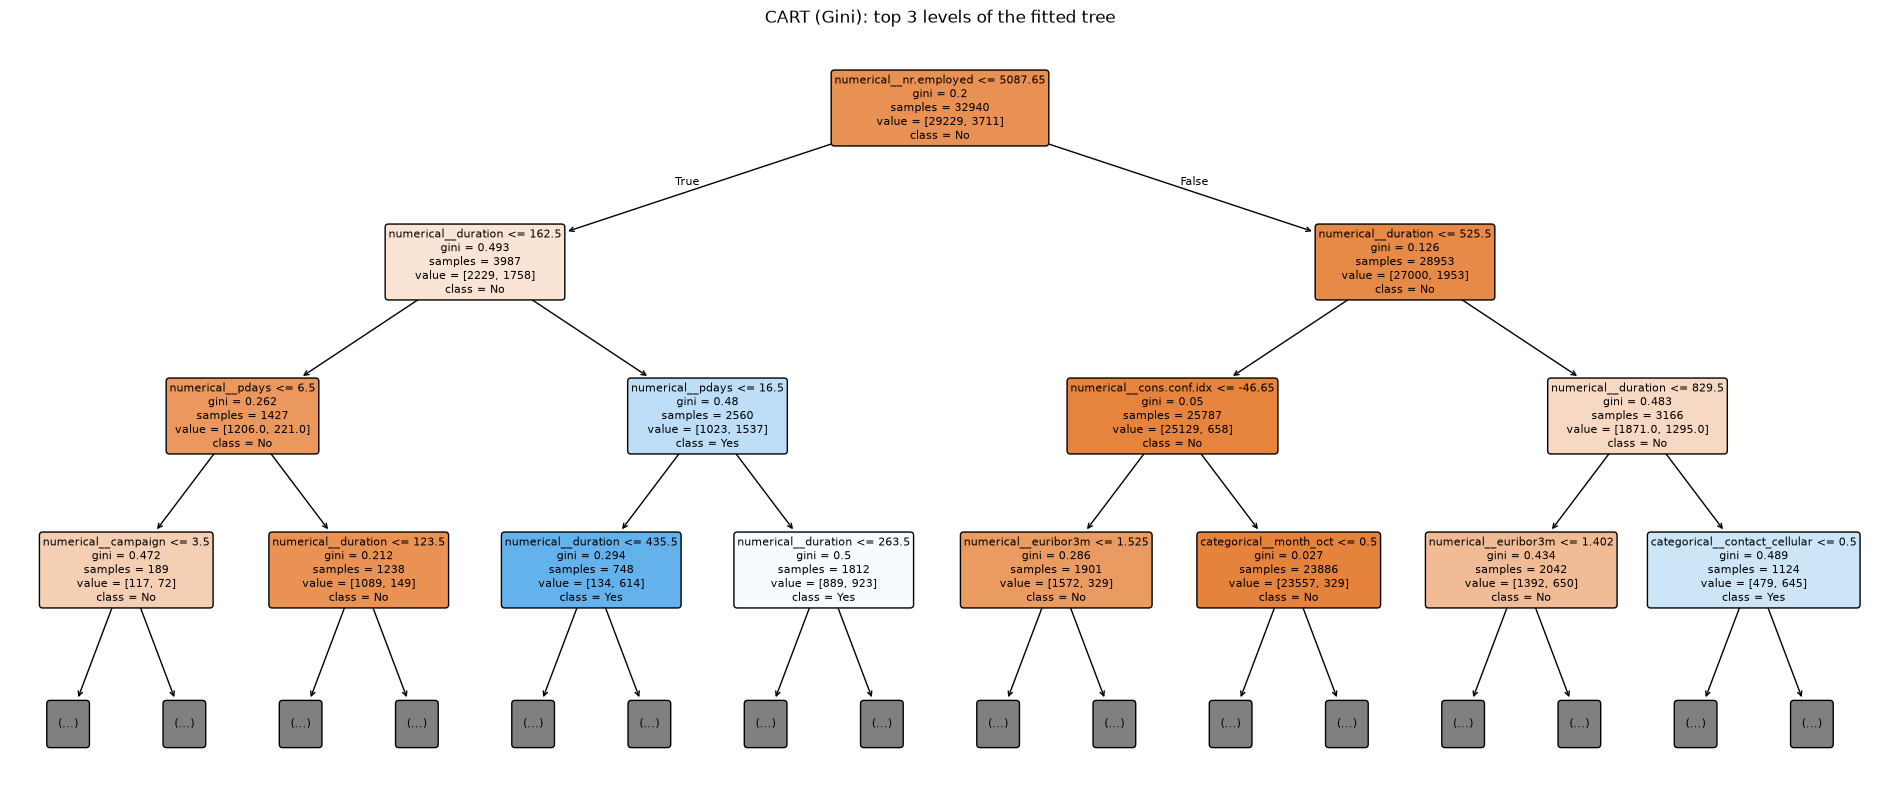

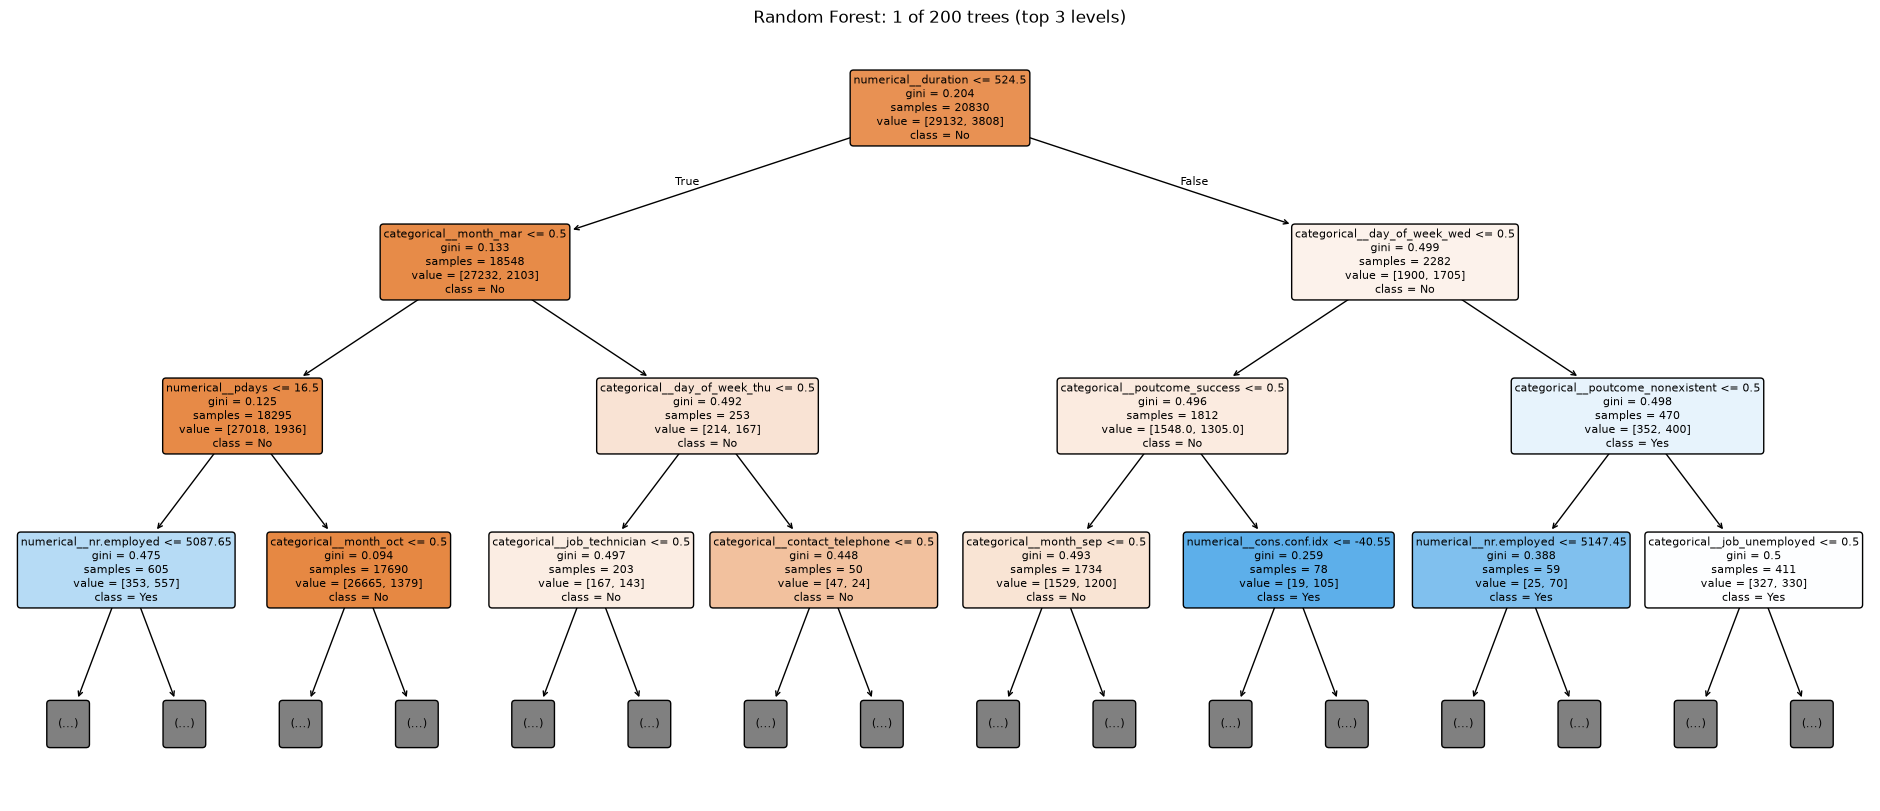

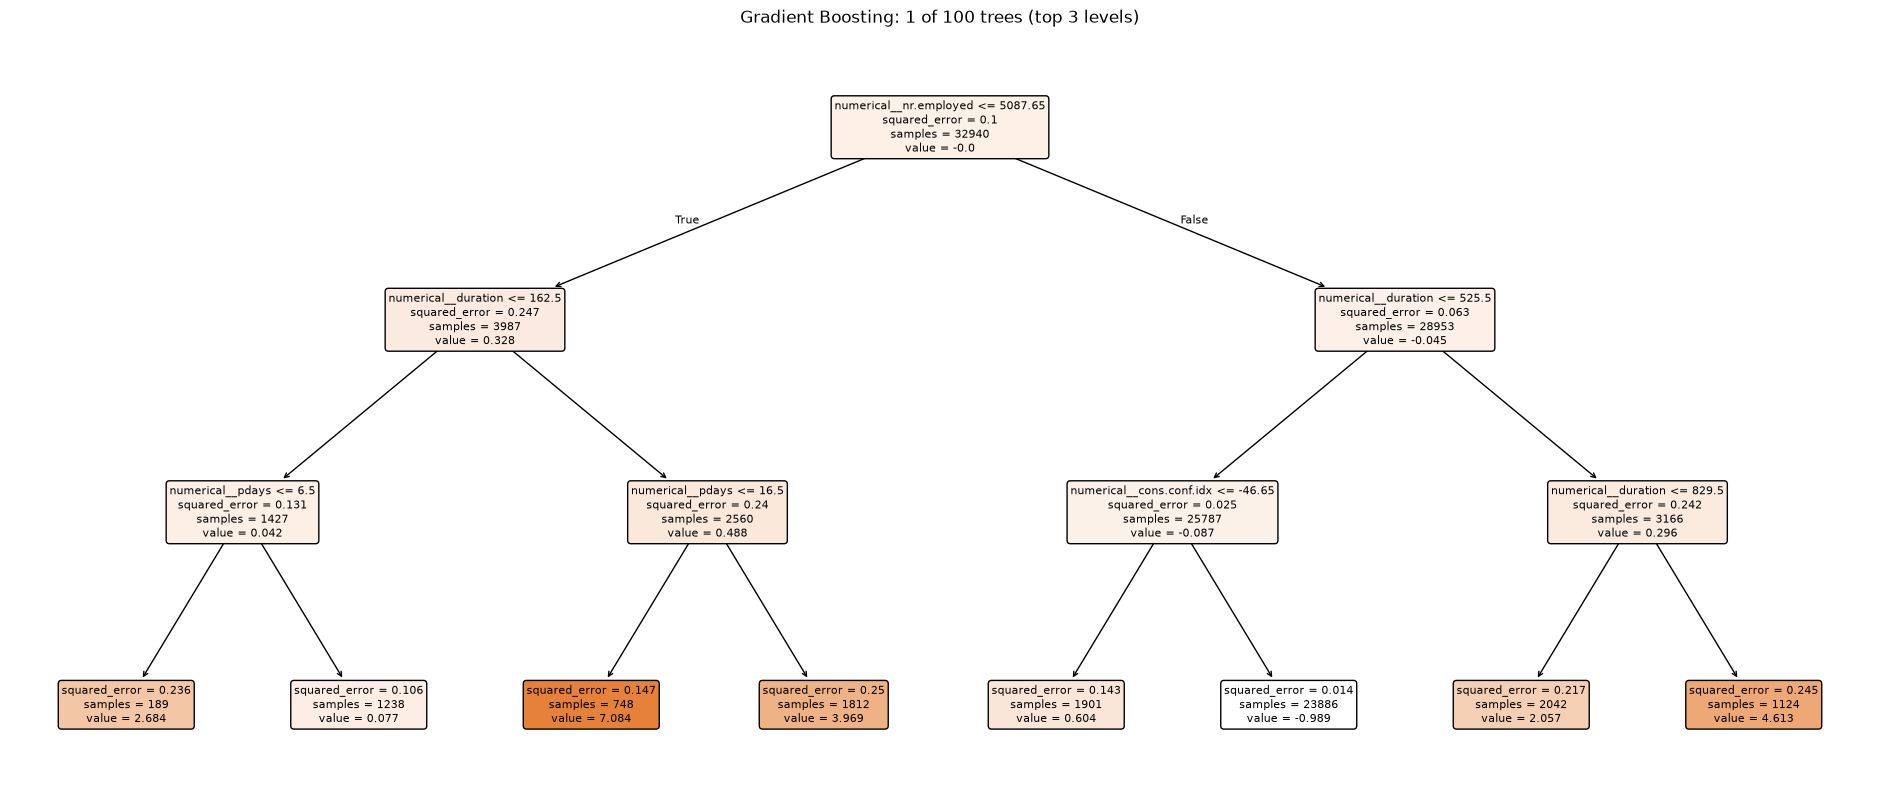

In [118]:
for model_name, pipeline in fitted_models.items():
    model = pipeline.steps[-1][1]
    feature_names = pipeline.named_steps["columntransformer"].get_feature_names_out()

    if model_name == "Random Forest":
        tree = model.estimators_[0]
        title = "Random Forest: 1 of 200 trees (top 3 levels)"
        class_names = ["No", "Yes"]
    elif model_name == "Gradient Boosting":
        tree = model.estimators_[0, 0]
        title = "Gradient Boosting: 1 of 100 trees (top 3 levels)"
        class_names = None
    elif model_name == "XGBoost":
        booster = model.get_booster()
        booster.feature_names = [
            str(name).replace("[", "(").replace("]", ")").replace("<", "lt")
            for name in feature_names
        ]
        continue
    else:
        tree = model
        title = f"{model_name}: top 3 levels of the fitted tree"
        class_names = ["No", "Yes"]

    plt.figure(figsize=(24, 10))
    plot_tree(
        tree,
        max_depth=3,
        feature_names=feature_names,
        class_names=class_names,
        filled=True,
        rounded=True,
        fontsize=8,
    )
    plt.title(title)
    plt.show()

In [119]:
report_rows = []

for model_name, predictions in test_predictions.items():
    report = classification_report(
        y_test,
        predictions,
        target_names=["No", "Yes"],
        zero_division=0,
        output_dict=True,
    )
    report_rows.append({
        "Model": model_name,
        "Accuracy": report["accuracy"],
        "No Precision": report["No"]["precision"],
        "No Recall": report["No"]["recall"],
        "No F1": report["No"]["f1-score"],
        "No Support": report["No"]["support"],
        "Yes Precision": report["Yes"]["precision"],
        "Yes Recall": report["Yes"]["recall"],
        "Yes F1": report["Yes"]["f1-score"],
        "Yes Support": report["Yes"]["support"],
    })

report_df = pd.DataFrame(report_rows)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", None)
display(report_df.round(4))

,Model,Accuracy,No Precision,No Recall,No F1,No Support,Yes Precision,Yes Recall,Yes F1,Yes Support
0,ID3-style (Entropy),0.9143,0.9394,0.9657,0.9524,7308.0,0.6533,0.5097,0.5726,928.0
1,CART (Gini),0.9151,0.9427,0.9629,0.9527,7308.0,0.6485,0.5388,0.5886,928.0
2,Random Forest,0.9105,0.9185,0.9867,0.9514,7308.0,0.7481,0.3103,0.4387,928.0
3,Gradient Boosting,0.9161,0.9433,0.9633,0.9532,7308.0,0.6533,0.5442,0.5938,928.0
4,XGBoost,0.9183,0.9449,0.9641,0.9544,7308.0,0.6637,0.5571,0.6057,928.0


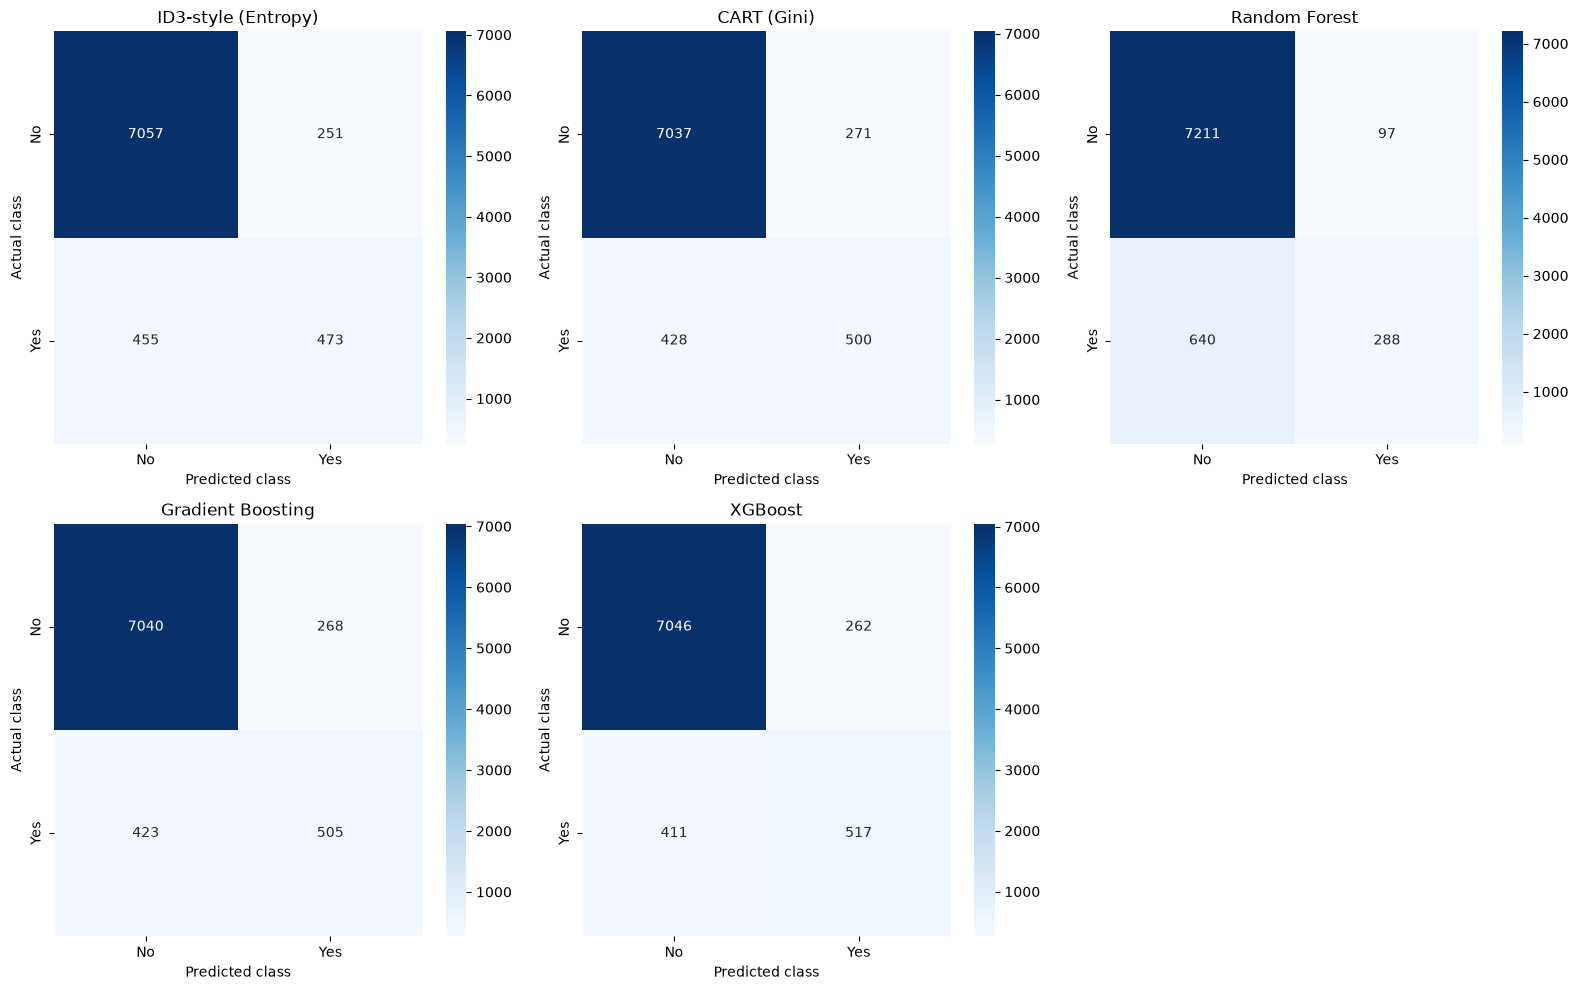

In [120]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for index, (model_name, predictions) in enumerate(test_predictions.items()):
    cm = confusion_matrix(y_test, predictions)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[index])
    axes[index].set_title(model_name)
    axes[index].set_xlabel("Predicted class")
    axes[index].set_ylabel("Actual class")
    axes[index].set_xticklabels(["No", "Yes"])
    axes[index].set_yticklabels(["No", "Yes"])

axes[-1].axis("off")
plt.tight_layout()
plt.show()

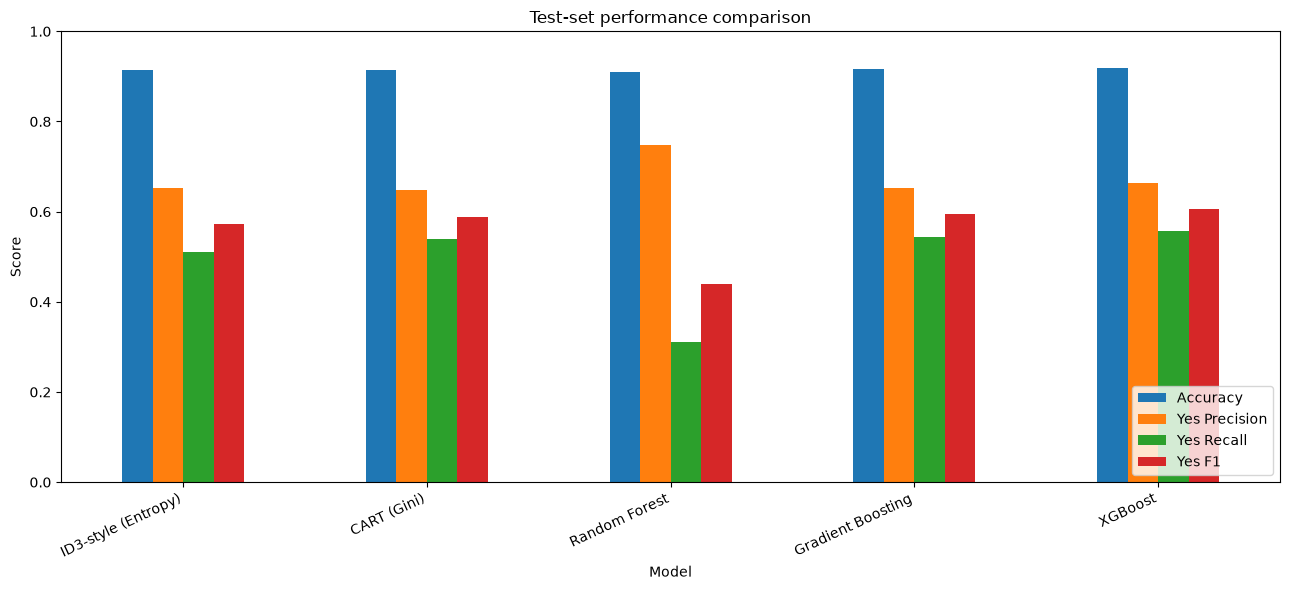

In [100]:
comparison = report_df.set_index("Model")[[
    "Accuracy", "Yes Precision", "Yes Recall", "Yes F1"
]]

comparison.plot(kind="bar", figsize=(13, 6))
plt.title("Test-set performance comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Meaning and limitations of the metrics

- **Accuracy** is the proportion of all clients classified correctly. Its limitation here is that the data are imbalanced which can end up obtain high accuracy mainly by predicting the majority `no` class.
- **Precision** is the proportion of predicted subscribers who actually subscribed. Its limitation is that a conservative model can achieve high precision while missing many subscribers.
- **Recall** is the proportion of actual subscribers correctly identified. It is important when the bank wants to miss as few potential subscribers as possible. Its limitation is that increasing recall can produce more false positives.
- **F1 score** is the mean of precision and recall. It provides a useful balance for the minority `yes` class, but it does not include true negatives and assumes precision and recall are equally important.


Algorithm XGBoost is better for Accuracy (0.9183)

Algorithm Random Forest is better for Yes Precision (0.7481)

Algorithm XGBoost is better for Yes Recall (0.5571)

Algorithm XGBoost is better for Yes F1 (0.6057)


In [121]:
metric_columns = ["Accuracy", "Yes Precision", "Yes Recall", "Yes F1"]

for metric in metric_columns:
    best_row = report_df.loc[report_df[metric].idxmax()]
    print(f"Algorithm {best_row['Model']} is better for {metric} ({best_row[metric]:.4f})")

Algorithm XGBoost is better for Accuracy (0.9183)
Algorithm Random Forest is better for Yes Precision (0.7481)
Algorithm XGBoost is better for Yes Recall (0.5571)
Algorithm XGBoost is better for Yes F1 (0.6057)
